In [55]:
#%% ============================================================
# Ground classification + Z-normalization for LAS tiles
# ============================================================
from pathlib import Path
import sys

# Add parent directory to path to import groundnorm
sys.path.insert(0, str(Path.cwd().parent))

from groundnorm import run_csf_ground_filter, run_smrf_ground_filter, normalize_las_z

import laspy
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap

# --- CONFIGURATION: Site 1 (DD0001) ---
SITE_NAME = "site1_DD0001"

INPUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/icp")
OUTPUT_BASE = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster")

GROUND_CSF_DIR = OUTPUT_BASE / "ground_classification" / "csf"
GROUND_SMRF_DIR = OUTPUT_BASE / "ground_classification" / "smrf"
# GROUND_CSF_FULL_DIR = OUTPUT_BASE / "ground_classification" / "csf"
# GROUND_SMRF_FULL_DIR = OUTPUT_BASE / "ground_classification" / "smrf"
ZNORM_CSF_DIR = OUTPUT_BASE / "z_norm" / "csf"
ZNORM_SMRF_DIR = OUTPUT_BASE / "z_norm" / "smrf"

for d in [GROUND_CSF_DIR, GROUND_SMRF_DIR, ZNORM_CSF_DIR, ZNORM_SMRF_DIR]:
    d.mkdir(parents=True, exist_ok=True)

LAS_PATTERN = "tiles_multispectral*.las"

print("--- Configuration ---")
print(f"Site: {SITE_NAME}")
print(f"Input dir: {INPUT_DIR}")
print(f"Output base: {OUTPUT_BASE}")
print(f"Pattern: {LAS_PATTERN}")
print("---------------------")

--- Configuration ---
Site: site1_DD0001
Input dir: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/icp
Output base: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster
Pattern: tiles_multispectral*.las
---------------------


In [56]:
# --- Find LAS files to process ---
import laspy

las_files = sorted(INPUT_DIR.glob(LAS_PATTERN))

if not las_files:
    print(f"❌ No LAS files found in {INPUT_DIR}")
else:
    print(f"Found {len(las_files)} LAS files to process")
    print("\nFirst 5 files:")
    for f in las_files[:5]:
        print(f"  {f.name}")
    
    # Inspect first file
    if las_files:
        sample = las_files[0]
        las = laspy.read(sample)
        print(f"\nSample file: {sample.name}")
        print(f"  Points: {len(las.points):,}")
        print(f"  Bounds:")
        print(f"    X: {las.header.mins[0]:.2f} → {las.header.maxs[0]:.2f}")
        print(f"    Y: {las.header.mins[1]:.2f} → {las.header.maxs[1]:.2f}")
        print(f"    Z: {las.header.mins[2]:.2f} → {las.header.maxs[2]:.2f}")

Found 15 LAS files to process

First 5 files:
  tiles_multispectral.106.las
  tiles_multispectral.109.las
  tiles_multispectral.113.las
  tiles_multispectral.121.las
  tiles_multispectral.16.las

Sample file: tiles_multispectral.106.las
  Points: 967,021
  Bounds:
    X: 461679.47 → 461710.18
    Y: 6237506.20 → 6237536.91
    Z: 57.80 → 62.75


In [57]:
#%% ------------------------------------------------------------
# Helper: label ground points (from ground-only LAS) onto the full LAS
# ------------------------------------------------------------
def label_ground_in_full_cloud(
    full_las_path: Path,
    ground_las_path: Path,
    out_las_path: Path,
    ground_class: int = 2,
    tol_xy: float = 0.02,   # 2 cm XY tolerance (adjust if needed)
    tol_z: float = 0.05     # 5 cm Z tolerance (adjust if needed)
) -> None:
    """
    Writes a new LAS where points in `full_las` that match `ground_las`
    are assigned Classification = ground_class.

    Matching is done by nearest-neighbour in XY, then Z is checked.
    Robust if point order differs between files.
    """
    full = laspy.read(full_las_path)
    ground = laspy.read(ground_las_path)

    full_xy = np.c_[full.x, full.y]
    g_xy = np.c_[ground.x, ground.y]

    tree = cKDTree(full_xy)
    d, idx = tree.query(g_xy, k=1, workers=-1)

    ok_xy = d <= tol_xy
    idx_ok = idx[ok_xy]

    g_z_ok = ground.z[ok_xy]
    full_z_at = full.z[idx_ok]
    ok_z = np.abs(full_z_at - g_z_ok) <= tol_z

    matched_full_idx = idx_ok[ok_z]

    cls = np.array(full.classification, copy=True)
    cls[matched_full_idx] = ground_class
    full.classification = cls

    out_las_path.parent.mkdir(parents=True, exist_ok=True)
    full.write(out_las_path)

    print(f"✅ Wrote classified LAS: {out_las_path}")
    print(f"   Ground points labelled: {len(matched_full_idx):,} ({len(matched_full_idx)/len(full.points)*100:.2f}%)")


In [58]:
# Helpers: downsampling + plotting
# ------------------------------------------------------------
def downsample_idx(n: int, max_pts: int) -> np.ndarray:
    if n > max_pts:
        return np.random.choice(n, size=max_pts, replace=False)
    return np.arange(n)

# 2-class colormap: non-ground light gray, ground green
GROUND_CMAP = ListedColormap(["lightgray", "limegreen"])

def plot_full_highlight_ground(ax, las: laspy.LasData, title: str, max_pts: int = 200_000):
    """
    Plot ALL points, but colour only by (classification==2):
      0 -> non-ground (light gray)
      1 -> ground (green)
    """
    idx = downsample_idx(len(las.points), max_pts)
    x = las.x[idx]
    y = las.y[idx]
    is_ground = (las.classification[idx] == 2).astype(np.uint8)

    sc = ax.scatter(x, y, s=1, c=is_ground, cmap=GROUND_CMAP, vmin=0, vmax=1, alpha=0.9)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal")
    cb = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cb.set_ticks([0, 1])
    cb.set_ticklabels(["non-ground", "ground (class 2)"])

def plot_ground_only(ax, las: laspy.LasData, title: str, max_pts: int = 200_000):
    """
    Plot only ground points (class 2), coloured by Z for context.
    """
    mask = las.classification == 2
    if mask.sum() == 0:
        ax.set_title(title + " (NO class 2 found!)", fontsize=13)
        return

    xg = las.x[mask]
    yg = las.y[mask]
    zg = las.z[mask]

    idx = downsample_idx(len(xg), max_pts)
    sc = ax.scatter(xg[idx], yg[idx], s=1, c=zg[idx], cmap="terrain", alpha=0.9)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal")
    plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04, label="Z (m)")

In [59]:
# --- Process single tile (for testing) ---
# Choose first tile
if las_files:
    test_tile = las_files[0]
    tile_name = test_tile.stem
    
    print(f"Processing test tile: {tile_name}")
    
    # CSF ground classification
    csf_ground = GROUND_CSF_DIR / f"csf_{tile_name}.las"
    print("\n=== Step 1: CSF Ground Classification ===")
    run_csf_ground_filter(
        input_las=test_tile,
        output_las=csf_ground,
        resolution=0.5,
        iterations=500,
        threshold=0.01,
        rigidness=2,
    )
    
    # SMRF ground classification
    smrf_ground = GROUND_SMRF_DIR / f"smrf_{tile_name}.las"
    print("\n=== Step 2: SMRF Ground Classification ===")
    run_smrf_ground_filter(
        input_las=test_tile,
        output_las=smrf_ground,
        slope=0.15,
        window=3.5,
        threshold=0.25,
        scalar=1.35,
    )
    
    # Z normalization with CSF
    znorm_csf = ZNORM_CSF_DIR / f"z_norm_csf_{tile_name}.las"
    print("\n=== Step 3a: Z Normalization (CSF) ===")
    normalize_las_z(
        input_las=test_tile,
        ground_las=csf_ground,
        output_las=znorm_csf,
        k=3,
        extra_dim_name="Z_norm",
    )
    
    # Z normalization with SMRF
    znorm_smrf = ZNORM_SMRF_DIR / f"z_norm_smrf_{tile_name}.las"
    print("\n=== Step 3b: Z Normalization (SMRF) ===")
    normalize_las_z(
        input_las=test_tile,
        ground_las=smrf_ground,
        output_las=znorm_smrf,
        k=3,
        extra_dim_name="Z_norm",
    )
    
    print("\n✅ Test tile processing complete!")

Processing test tile: tiles_multispectral.106

=== Step 1: CSF Ground Classification ===
💾 Saved PDAL CSF pipeline: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/ground_classification/csf/csf_tiles_multispectral.106.json
▶️  Running PDAL CSF on tiles_multispectral.106.las


(PDAL Debug) Debugging...
(pdal pipeline Debug) Executing pipeline in standard mode.


(pdal pipeline filters.csf Debug) setPointCloud: 924122
(pdal pipeline filters.csf Debug) [0] Configuring terrain...
(pdal pipeline filters.csf Debug) 461710, 461679
(pdal pipeline filters.csf Debug) [0] Configuring cloth...
(pdal pipeline filters.csf Debug) [0]  - width: 65 height: 65
(pdal pipeline filters.csf Debug) [0] Rasterizing...
(pdal pipeline filters.csf Debug) [0] Simulating...
(pdal pipeline writers.las Debug) Wrote 271659 points to the LAS file


✅ CSF ground LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/ground_classification/csf/csf_tiles_multispectral.106.las

=== Step 2: SMRF Ground Classification ===
💾 Saved PDAL SMRF pipeline: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/ground_classification/smrf/smrf_tiles_multispectral.106.json
▶️  Running PDAL SMRF on tiles_multispectral.106.las
✅ SMRF ground LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/ground_classification/smrf/smrf_tiles_multispectral.106.las

=== Step 3a: Z Normalization (CSF) ===
✅ Wrote normalized LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/z_norm/csf/z_norm_csf_tiles_multispectral.106.las
   HAG stats (m): min=0.000, median=0.012, max=4.420
   Ground pts: 271,659, All pts: 967,021, k=3

=== Step 3b: Z Normalization (SMRF) ===
✅ Wrote normalized LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/z_norm/smrf/z_norm_smrf_tiles_multispectral.106.las
   HAG stats (m): min=0.000, media

In [60]:
#%% ------------------------------------------------------------
# Quick classification sanity check
# ------------------------------------------------------------
def print_class_hist(las_path: Path, label: str) -> None:
    las = laspy.read(las_path)
    u, c = np.unique(las.classification, return_counts=True)
    hist = dict(zip(u.tolist(), c.tolist()))
    print(f"\n{label}: {las_path.name}")
    print("  classification histogram:", hist)

print_class_hist(csf_ground, "CSF FULL (expected class 2 present)")
print_class_hist(smrf_ground, "SMRF FULL (expected class 2 present)")



CSF FULL (expected class 2 present): csf_tiles_multispectral.106.las
  classification histogram: {2: 271659}

SMRF FULL (expected class 2 present): smrf_tiles_multispectral.106.las
  classification histogram: {2: 785243}


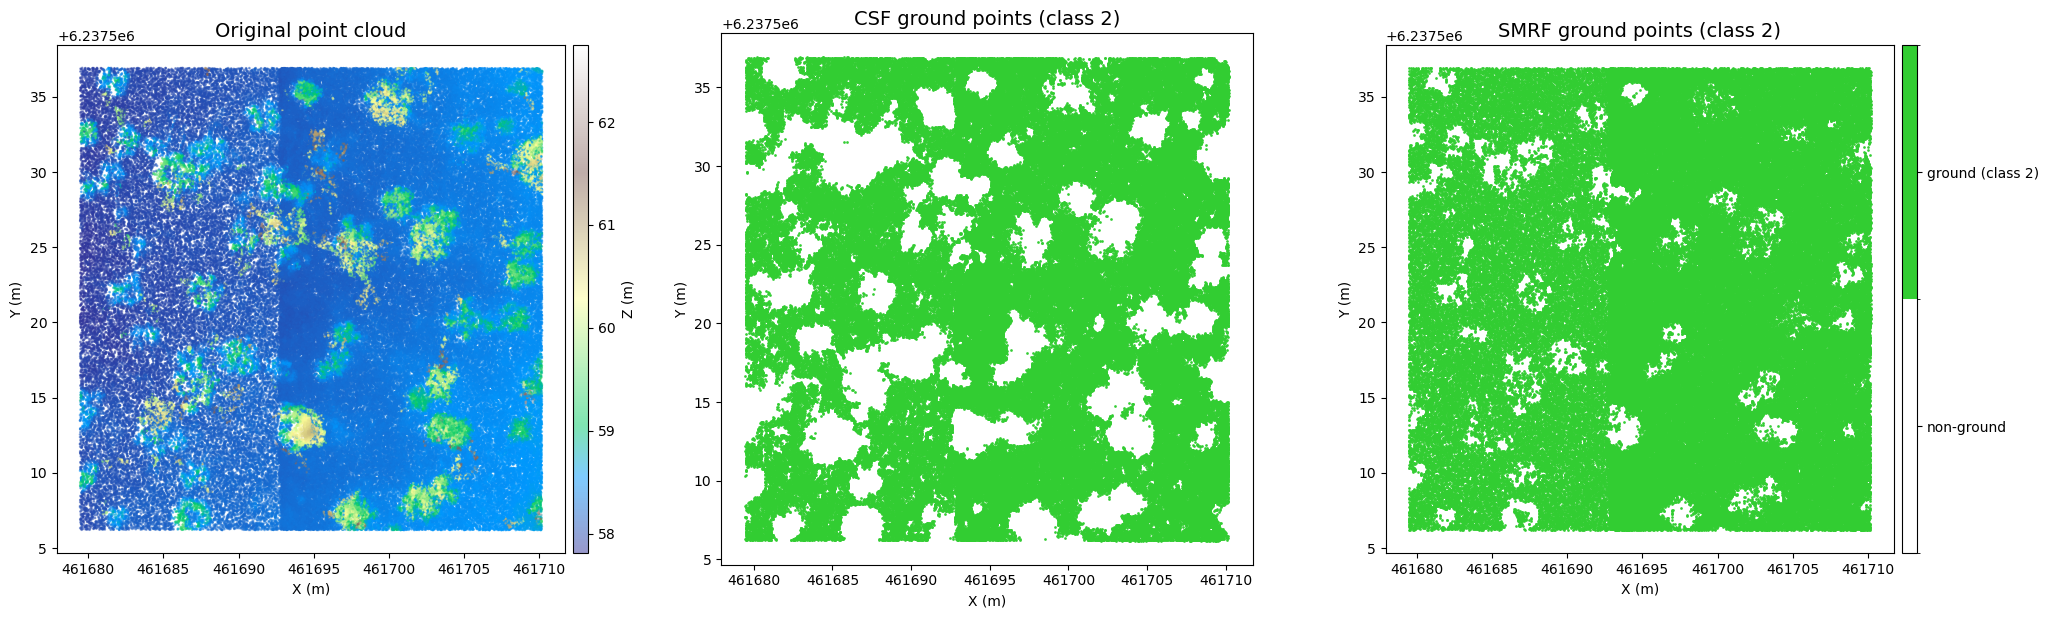

In [61]:
#%% --- Visualize: Original (Z) + CSF/SMRF ground-only + ONE classification bar like Image 1 ---
import numpy as np
import matplotlib.pyplot as plt
import laspy
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1 import make_axes_locatable


max_pts = 200_000

def downsample_idx(n: int, max_pts: int) -> np.ndarray:
    if n > max_pts:
        return np.random.choice(n, size=max_pts, replace=False)
    return np.arange(n)

def plot_ground_only(ax, las, title, max_pts=200_000):
    """Plot ONLY ground points (class 2) in green. No colorbar here."""
    x = np.asarray(las.x)
    y = np.asarray(las.y)
    cls = np.asarray(las.classification)

    idx = downsample_idx(len(x), max_pts)
    x, y, cls = x[idx], y[idx], cls[idx]

    mask = (cls == 2)
    ax.scatter(x[mask], y[mask], s=1, c="limegreen", alpha=0.9)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal")

# --- Load LAS ---
las_orig = laspy.read(test_tile)
las_csf_full = laspy.read(csf_ground)
las_smrf_full = laspy.read(smrf_ground)

# Downsample original for Z plot
idx0 = downsample_idx(len(las_orig.points), max_pts)
x_orig = las_orig.x[idx0]
y_orig = las_orig.y[idx0]
z_orig = las_orig.z[idx0]

# --- Figure ---
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
fig.subplots_adjust(wspace=0.25)  # leave space between panels (avoid tight_layout issues)

# (1) Original Z-coloured (keep as you had)
# (1) Original Z-coloured (same-height external colourbar)
ax = axes[0]
sc0 = ax.scatter(x_orig, y_orig, s=1, c=z_orig, cmap="terrain", alpha=0.5)
ax.set_title("Original point cloud", fontsize=14)
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_aspect("equal")

divider0 = make_axes_locatable(ax)
cax0 = divider0.append_axes("right", size="3%", pad=0.08)  # same height as plot
cbar0 = fig.colorbar(sc0, cax=cax0)
cbar0.set_label("Z (m)")


# (2) CSF ground-only
plot_ground_only(axes[1], las_csf_full, "CSF ground points (class 2)", max_pts=max_pts)

# (3) SMRF ground-only
plot_ground_only(axes[2], las_smrf_full, "SMRF ground points (class 2)", max_pts=max_pts)

# --- ONE classification bar (grey/green) OUTSIDE right of last plot, same height (like Image 1) ---
class_cmap = ListedColormap(["white", "limegreen"])
class_norm = BoundaryNorm([0, 0.5, 1.0], class_cmap.N)  # 0=non-ground, 1=ground

mappable = ScalarMappable(cmap=class_cmap, norm=class_norm)
mappable.set_array([])

divider = make_axes_locatable(axes[2])
cax = divider.append_axes("right", size="3%", pad=0.08)  # outside, same height

cbar = fig.colorbar(mappable, cax=cax)
cbar.set_ticks([0.25, 0.75])
cbar.set_ticklabels(["non-ground", "ground (class 2)"])

plt.show()


Z_norm statistics:

CSF:
  Min: 0.000 m
  Mean: 0.248 m
  Median: 0.012 m
  Max: 4.420 m

SMRF:
  Min: 0.000 m
  Mean: 0.200 m
  Median: 0.000 m
  Max: 4.430 m



💾 Figure saved to: /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_2_csf_znorm/outputs/hag_visualization_tiles_multispectral.106.png


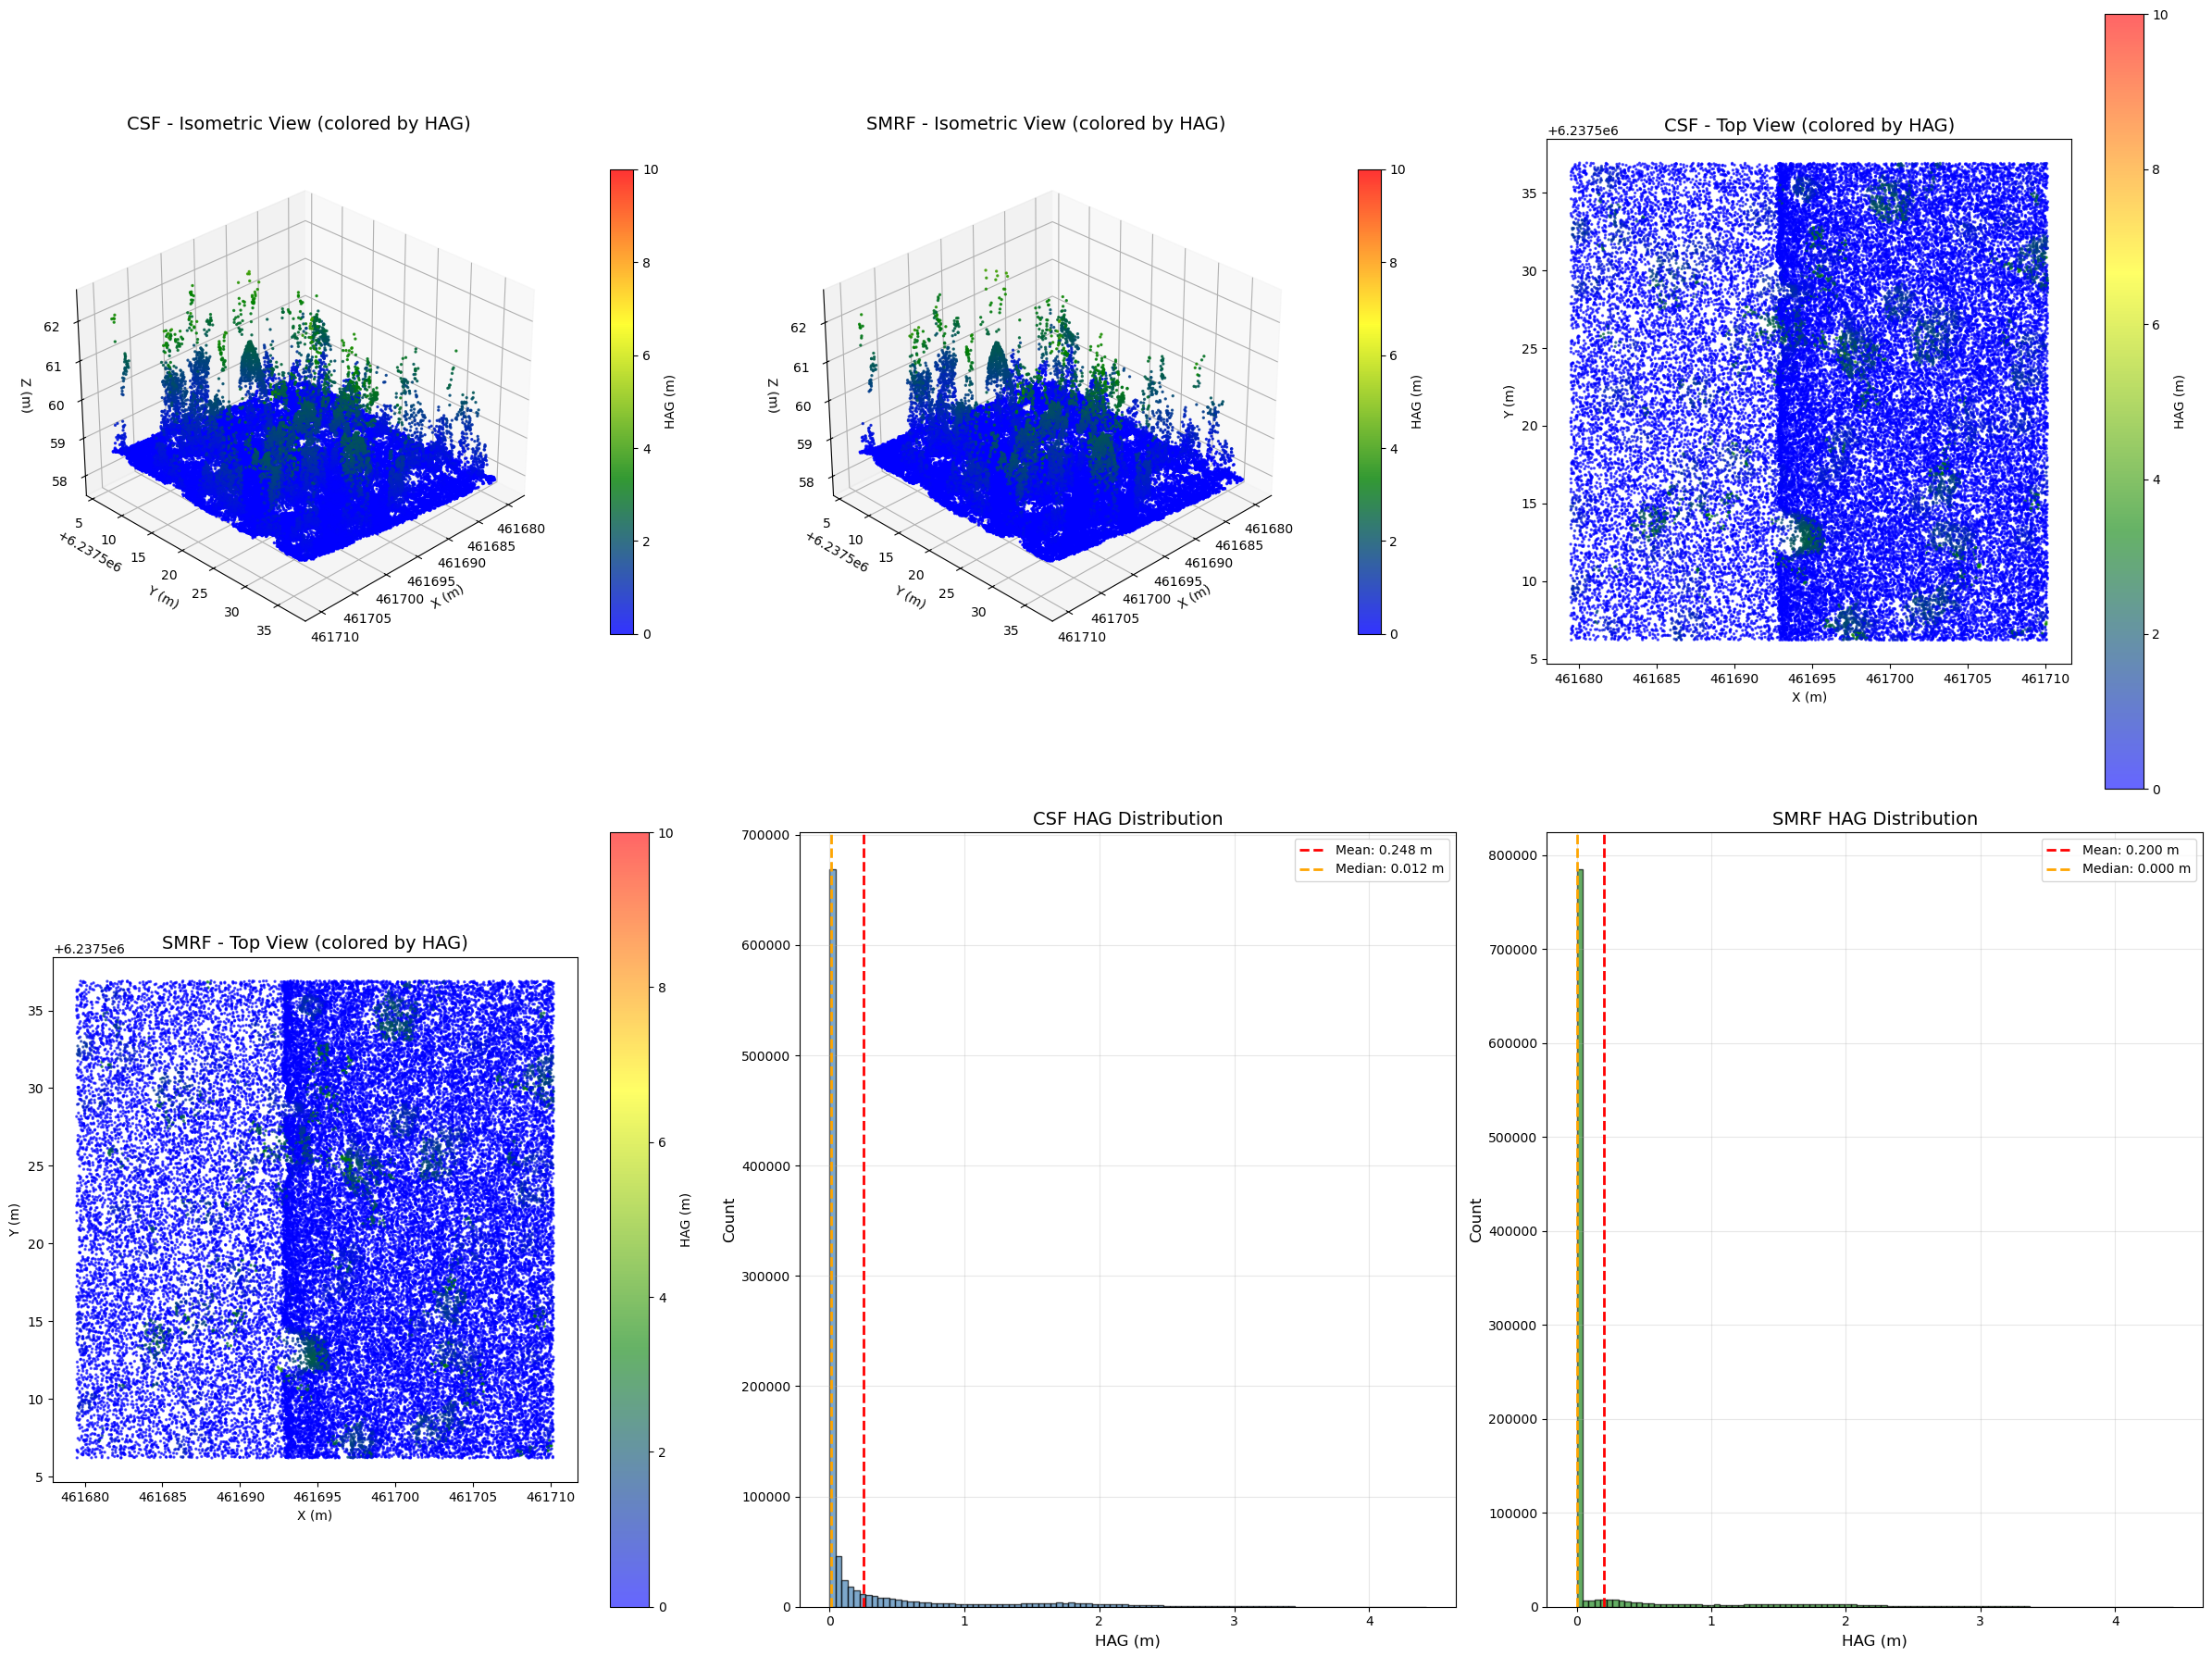


✅ 3D isometric + top view visualization complete!


In [67]:
# --- Visualize Z normalization results (3D Isometric + Top View) ---
from mpl_toolkits.mplot3d import Axes3D
from scipy.ndimage import gaussian_filter
from matplotlib.colors import LinearSegmentedColormap

if las_files:
    # Load normalized point clouds
    las_znorm_csf = laspy.read(znorm_csf)
    las_znorm_smrf = laspy.read(znorm_smrf)
    
    # Extract Z_norm values (HAG)
    z_norm_csf = np.asarray(las_znorm_csf.Z_norm, dtype=np.float32)
    z_norm_smrf = np.asarray(las_znorm_smrf.Z_norm, dtype=np.float32)
    
    print("Z_norm statistics:")
    print(f"\nCSF:")
    print(f"  Min: {z_norm_csf.min():.3f} m")
    print(f"  Mean: {z_norm_csf.mean():.3f} m")
    print(f"  Median: {np.median(z_norm_csf):.3f} m")
    print(f"  Max: {z_norm_csf.max():.3f} m")
    
    print(f"\nSMRF:")
    print(f"  Min: {z_norm_smrf.min():.3f} m")
    print(f"  Mean: {z_norm_smrf.mean():.3f} m")
    print(f"  Median: {np.median(z_norm_smrf):.3f} m")
    print(f"  Max: {z_norm_smrf.max():.3f} m")
    
    # Create custom colormap: blue -> green -> yellow -> red
    colors_bgyr = ['blue', 'green', 'yellow', 'red']
    n_bins = 256
    cmap_bgyr = LinearSegmentedColormap.from_list('bgyr', colors_bgyr, N=n_bins)
    
    # Downsample for visualization
    max_pts_3d = 50000  # Fewer points for 3D
    
    # For 3D plots, we need actual X, Y, Z coordinates but color by Z_norm (HAG)
    def downsample_with_znorm(las_obj, z_norm_vals, max_pts):
        n = len(las_obj.x)
        if n > max_pts:
            idx = np.random.choice(n, size=max_pts, replace=False)
            return las_obj.x[idx], las_obj.y[idx], las_obj.z[idx], z_norm_vals[idx]
        return las_obj.x, las_obj.y, las_obj.z, z_norm_vals
    
    x_csf_n, y_csf_n, z_csf_n, hag_csf_n = downsample_with_znorm(las_znorm_csf, z_norm_csf, max_pts_3d)
    x_smrf_n, y_smrf_n, z_smrf_n, hag_smrf_n = downsample_with_znorm(las_znorm_smrf, z_norm_smrf, max_pts_3d)
    
    # Create visualization with 3D isometric and top views
    fig = plt.figure(figsize=(24, 18))
    
    # CSF HAG (3D Isometric)
    ax = fig.add_subplot(2, 3, 1, projection='3d')
    sc = ax.scatter(x_csf_n, y_csf_n, z_csf_n, s=2, c=hag_csf_n, cmap=cmap_bgyr, alpha=0.8, vmin=0, vmax=10)
    ax.set_title('CSF - Isometric View (colored by HAG)', fontsize=14, pad=20)
    ax.set_xlabel('X (m)', fontsize=10)
    ax.set_ylabel('Y (m)', fontsize=10)
    ax.set_zlabel('Z (m)', fontsize=10)
    ax.view_init(elev=30, azim=45)  # Isometric view
    plt.colorbar(sc, ax=ax, label='HAG (m)', shrink=0.6, pad=0.1)
    
    # SMRF HAG (3D Isometric)
    ax = fig.add_subplot(2, 3, 2, projection='3d')
    sc = ax.scatter(x_smrf_n, y_smrf_n, z_smrf_n, s=2, c=hag_smrf_n, cmap=cmap_bgyr, alpha=0.8, vmin=0, vmax=10)
    ax.set_title('SMRF - Isometric View (colored by HAG)', fontsize=14, pad=20)
    ax.set_xlabel('X (m)', fontsize=10)
    ax.set_ylabel('Y (m)', fontsize=10)
    ax.set_zlabel('Z (m)', fontsize=10)
    ax.view_init(elev=30, azim=45)  # Isometric view
    plt.colorbar(sc, ax=ax, label='HAG (m)', shrink=0.6, pad=0.1)
    
    # CSF HAG (Top View - 2D)
    ax = fig.add_subplot(2, 3, 3)
    sc = ax.scatter(x_csf_n, y_csf_n, s=2, c=hag_csf_n, cmap=cmap_bgyr, alpha=0.6, vmin=0, vmax=10)
    ax.set_title('CSF - Top View (colored by HAG)', fontsize=14)
    ax.set_xlabel('X (m)', fontsize=10)
    ax.set_ylabel('Y (m)', fontsize=10)
    ax.set_aspect('equal')
    plt.colorbar(sc, ax=ax, label='HAG (m)')
    
    # SMRF HAG (Top View - 2D)
    ax = fig.add_subplot(2, 3, 4)
    sc = ax.scatter(x_smrf_n, y_smrf_n, s=2, c=hag_smrf_n, cmap=cmap_bgyr, alpha=0.6, vmin=0, vmax=10)
    ax.set_title('SMRF - Top View (colored by HAG)', fontsize=14)
    ax.set_xlabel('X (m)', fontsize=10)
    ax.set_ylabel('Y (m)', fontsize=10)
    ax.set_aspect('equal')
    plt.colorbar(sc, ax=ax, label='HAG (m)')
    
    # CSF histogram
    ax = fig.add_subplot(2, 3, 5)
    ax.hist(z_norm_csf, bins=100, edgecolor='black', alpha=0.7, color='steelblue')
    ax.axvline(z_norm_csf.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {z_norm_csf.mean():.3f} m')
    ax.axvline(np.median(z_norm_csf), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(z_norm_csf):.3f} m')
    ax.set_xlabel('HAG (m)', fontsize=12)
    ax.set_ylabel('Count', fontsize=12)
    ax.set_title('CSF HAG Distribution', fontsize=14)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    # SMRF histogram
    ax = fig.add_subplot(2, 3, 6)
    ax.hist(z_norm_smrf, bins=100, edgecolor='black', alpha=0.7, color='forestgreen')
    ax.axvline(z_norm_smrf.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {z_norm_smrf.mean():.3f} m')
    ax.axvline(np.median(z_norm_smrf), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(z_norm_smrf):.3f} m')
    ax.set_xlabel('HAG (m)', fontsize=12)
    ax.set_ylabel('Count', fontsize=12)
    ax.set_title('SMRF HAG Distribution', fontsize=14)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save high-quality figure (SSH-friendly)
    output_dir = Path.cwd().parent / 'outputs'
    output_dir.mkdir(exist_ok=True)
    output_path = output_dir / f'hag_visualization_{tile_name}.png'
    plt.savefig(output_path, dpi=200, bbox_inches='tight')
    print(f"\n💾 Figure saved to: {output_path}")
    
    plt.show()
    
    print("\n✅ 3D isometric + top view visualization complete!")


In [ ]:

# # --- Interactive PyVista Visualization with True EDL Shading ---
# try:
#     import pyvista as pv
#     pyvista_available = True
# except ImportError:
#     pyvista_available = False
#     print("⚠️ PyVista not installed. Install with: pip install pyvista")

# if pyvista_available:
#     print("Creating interactive PyVista visualization with Eye Dome Lighting...")
    
#     # Load a specific z_norm file (can change to znorm_csf if processed)
#     las_file = Path('/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/z_norm/csf/z_norm_csf_tiles_multispectral.106.las')
    
#     if las_file.exists():
#         las_viz = laspy.read(las_file)
#         z_norm_viz = np.asarray(las_viz.Z_norm, dtype=np.float32)
        
#         print(f"Loaded: {las_file.name}")
#         print(f"Points: {len(las_viz.points):,}")
#         print(f"HAG range: {z_norm_viz.min():.3f} - {z_norm_viz.max():.3f} m")
        
#         # Downsample for better performance
#         max_pts_pv = 200000
#         n = len(las_viz.x)
#         if n > max_pts_pv:
#             idx = np.random.choice(n, size=max_pts_pv, replace=False)
#             x_pv = las_viz.x[idx]
#             y_pv = las_viz.y[idx]
#             z_pv = las_viz.z[idx]
#             hag_pv = z_norm_viz[idx]
#         else:
#             x_pv = las_viz.x
#             y_pv = las_viz.y
#             z_pv = las_viz.z
#             hag_pv = z_norm_viz
        
#         # Center the point cloud
#         x_center = (x_pv.max() + x_pv.min()) / 2
#         y_center = (y_pv.max() + y_pv.min()) / 2
#         z_center = (z_pv.max() + z_pv.min()) / 2
        
#         x_pv_centered = x_pv - x_center
#         y_pv_centered = y_pv - y_center
#         z_pv_centered = z_pv - z_center
        
#         # Create PyVista point cloud with centered coordinates
#         points = np.column_stack([x_pv_centered, y_pv_centered, z_pv_centered])
#         point_cloud = pv.PolyData(points)
#         point_cloud['Z_norm'] = hag_pv
        
#         # Create custom colormap: blue -> green -> yellow -> red
#         import matplotlib.pyplot as plt
#         from matplotlib.colors import LinearSegmentedColormap, to_hex
#         colors_bgyr = ['blue', 'green', 'yellow', 'red']
#         n_colors = 256
#         cmap_bgyr = LinearSegmentedColormap.from_list('bgyr', colors_bgyr, N=n_colors)
#         # Convert to list of hex color strings for PyVista
#         colormap_hex = [to_hex(cmap_bgyr(i / (n_colors - 1))) for i in range(n_colors)]
        
#         print(f"Point cloud centered at origin")
#         print(f"Bounds: X=[{x_pv_centered.min():.1f}, {x_pv_centered.max():.1f}], "
#               f"Y=[{y_pv_centered.min():.1f}, {y_pv_centered.max():.1f}], "
#               f"Z=[{z_pv_centered.min():.1f}, {z_pv_centered.max():.1f}]")
        
#         # Create plotter with side-by-side comparison
#         plotter = pv.Plotter(window_size=[1600, 800], shape=(1, 2))
        
#         # Left: Standard rendering
#         plotter.subplot(0, 0)
#         plotter.add_mesh(
#             point_cloud,
#             scalars='Z_norm',
#             cmap=colormap_hex,
#             point_size=3,
#             render_points_as_spheres=True,
#             clim=[0, 5],
#             scalar_bar_args={
#                 'title': 'HAG (m)',
#                 'vertical': True,
#                 'position_x': 0.85,
#                 'position_y': 0.1,
#             }
#         )
#         plotter.add_text("Standard Rendering", font_size=14, position='upper_edge')
#         plotter.view_isometric()
#         plotter.reset_camera()
#         plotter.camera.zoom(1.2)
        
#         # Right: EDL rendering for depth perception
#         plotter.subplot(0, 1)
#         plotter.add_mesh(
#             point_cloud,
#             scalars='Z_norm',
#             cmap=colormap_hex,
#             point_size=3,
#             render_points_as_spheres=True,
#             clim=[0, 5],
#             scalar_bar_args={
#                 'title': 'HAG (m)',
#                 'vertical': True,
#                 'position_x': 0.85,
#                 'position_y': 0.1,
#             }
#         )
#         plotter.add_text("Eye Dome Lighting (EDL)", font_size=14, position='upper_edge')
#         plotter.enable_eye_dome_lighting()  # True EDL shader
#         plotter.view_isometric()
#         plotter.reset_camera()
#         plotter.camera.zoom(1.2)
        
#         # Add instructions
#         print("\n" + "="*60)
#         print("PyVista Interactive Viewer Controls:")
#         print("="*60)
#         print("  • Left mouse: Rotate")
#         print("  • Middle mouse / Shift+Left: Pan")
#         print("  • Scroll wheel: Zoom")
#         print("  • 'r': Reset camera")
#         print("  • 'q': Close window")
#         print("  • 's': Save screenshot")
#         print("="*60)
        
#         # Show interactive plot
#         plotter.show()
        
#         print("\n✅ PyVista visualization complete!")
#         print("   EDL shading provides enhanced depth perception")
#         print("   Colormap: Blue (ground) → Green → Yellow → Red (tall vegetation)")
#     else:
#         print(f"❌ File not found: {las_file}")
#         print("   Process a tile first or change the file path")
# else:
#     print("\n💡 To enable interactive 3D visualization with true EDL shading:")
#     print("   pip install pyvista")

Creating interactive PyVista visualization with Eye Dome Lighting...
Loaded: z_norm_csf_tiles_multispectral.106.las
Points: 967,021
HAG range: 0.000 - 4.420 m
Point cloud centered at origin
Bounds: X=[-15.4, 15.4], Y=[-15.4, 15.4], Z=[-2.4, 2.4]

PyVista Interactive Viewer Controls:
  • Left mouse: Rotate
  • Middle mouse / Shift+Left: Pan
  • Scroll wheel: Zoom
  • 'r': Reset camera
  • 'q': Close window
  • 's': Save screenshot


Widget(value='<iframe src="http://localhost:43203/index.html?ui=P_0x7e787f5ce2f0_3&reconnect=auto" class="pyvi…


✅ PyVista visualization complete!
   EDL shading provides enhanced depth perception
   Colormap: Blue (ground) → Green → Yellow → Red (tall vegetation)


In [ ]:
# --- Interactive LAS File + View + Params (CSF/SMRF shown properly) ---
import ipywidgets as widgets
from IPython.display import display, clear_output
import laspy
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
from mpl_toolkits.axes_grid1 import make_axes_locatable

# -----------------------------
# Helpers
# -----------------------------
def list_las_files(input_dir, pattern):
    return sorted([str(f) for f in Path(input_dir).glob(pattern)])

def get_bgyr_cmap():
    colors_bgyr = ["blue", "green", "yellow", "red"]
    return LinearSegmentedColormap.from_list("bgyr", colors_bgyr, N=256)

def downsample_arrays(*arrs, max_pts=50_000, seed=42):
    n = len(arrs[0])
    if n <= max_pts:
        return arrs
    rng = np.random.default_rng(seed)
    idx = rng.choice(n, size=max_pts, replace=False)
    return tuple(a[idx] for a in arrs)

def add_same_height_colorbar(fig, ax, mappable, label=None, ticks=None, ticklabels=None, size="3%", pad=0.08):
    """External colorbar, same height as plot (like your reference)."""
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size=size, pad=pad)
    cbar = fig.colorbar(mappable, cax=cax)
    if label:
        cbar.set_label(label)
    if ticks is not None:
        cbar.set_ticks(ticks)
    if ticklabels is not None:
        cbar.set_ticklabels(ticklabels)
    return cbar

# Discrete (two-block) classification bar like Image 1
CLASS_CMAP = ListedColormap(["lightgray", "limegreen"])
CLASS_NORM = BoundaryNorm([0, 0.5, 1.0], CLASS_CMAP.N)
CLASS_MAPPABLE = ScalarMappable(cmap=CLASS_CMAP, norm=CLASS_NORM)
CLASS_MAPPABLE.set_array([])

def resolve_view_path(las_path_str, view):
    """
    Returns (path_to_read, mode)
      mode:
        - "z"        : colour by Z
        - "znorm"    : colour by Z_norm
        - "class2"   : show full cloud, highlight class2 (discrete bar)
        - "ground_z" : ground only, colour by Z
    """
    p = Path(las_path_str)
    stem = p.stem

    if view == "Original":
        return p, "z"

    # Full cloud with classification==2 labelled (the fixed outputs)
    if view == "CSF ground (class 2)":
        return (GROUND_CSF_DIR / f"csf_{stem}.las"), "class2"
    if view == "SMRF ground (class 2)":
        return (GROUND_SMRF_DIR / f"smrf_{stem}.las"), "class2"


    # Z_norm outputs
    if view == "Z_norm_CSF":
        return (ZNORM_CSF_DIR / f"z_norm_csf_{stem}.las"), "znorm"
    if view == "Z_norm_SMRF":
        return (ZNORM_SMRF_DIR / f"z_norm_smrf_{stem}.las"), "znorm"

    raise ValueError(f"Unknown view: {view}")

# -----------------------------
# Widgets
# -----------------------------
las_file_widget = widgets.Dropdown(
    options=list_las_files(INPUT_DIR, LAS_PATTERN),
    description="LAS File:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="90%"),
)

view_widget = widgets.ToggleButtons(
    options=[
        "Original",
        "CSF ground (class 2)",
        "SMRF ground (class 2)",
        "Z_norm_CSF",
        "Z_norm_SMRF",
    ],
    description="View:",
    style={"description_width": "initial"},
)


colormap_widget = widgets.Dropdown(
    options=["terrain", "viridis", "plasma", "bgyr"],
    value="terrain",
    description="Colormap (Z/Z_norm):",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="45%"),
)

point_size_widget = widgets.IntSlider(
    value=1, min=1, max=8, step=1,
    description="Point Size:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="45%"),
)

max_pts_widget = widgets.IntSlider(
    value=50_000, min=10_000, max=200_000, step=10_000,
    description="Max Points:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="45%"),
)

alpha_widget = widgets.FloatSlider(
    value=0.8, min=0.1, max=1.0, step=0.1,
    description="Alpha:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="45%"),
)

hag_min_widget = widgets.FloatSlider(
    value=0.0, min=0.0, max=10.0, step=0.1,
    description="HAG Min:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="45%"),
)

hag_max_widget = widgets.FloatSlider(
    value=5.0, min=0.1, max=30.0, step=0.1,
    description="HAG Max:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="45%"),
)

update_button = widgets.Button(description="Update", button_style="primary")

# Auto-enable HAG sliders only for Z_norm views
def sync_hag_visibility(*args):
    is_znorm = view_widget.value in ("Z_norm_CSF", "Z_norm_SMRF")
    hag_min_widget.disabled = not is_znorm
    hag_max_widget.disabled = not is_znorm

view_widget.observe(sync_hag_visibility, names="value")
sync_hag_visibility()

# -----------------------------
# Plot function
# -----------------------------
def plot_las_interactive(las_path_str, view, colormap, point_size, alpha, max_pts, hag_min, hag_max):
    path, mode = resolve_view_path(las_path_str, view)
    if not path.exists():
        print(f"❌ File not found for view '{view}':\n   {path}")
        return

    las = laspy.read(path)
    x = np.asarray(las.x)
    y = np.asarray(las.y)

    fig, ax = plt.subplots(figsize=(10, 8))

    if mode == "z":
        z = np.asarray(las.z)
        x, y, z = downsample_arrays(x, y, z, max_pts=max_pts)
        cmap = get_bgyr_cmap() if colormap == "bgyr" else colormap
        sc = ax.scatter(x, y, s=point_size, c=z, cmap=cmap, alpha=alpha)
        ax.set_title(f"{view} – {Path(las_path_str).name}")
        ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.set_aspect("equal")
        add_same_height_colorbar(fig, ax, sc, label="Z (m)")

    elif mode == "znorm":
        if not hasattr(las, "Z_norm"):
            print("❌ This LAS does not contain extra dim 'Z_norm'.")
            return
        zn = np.asarray(las.Z_norm, dtype=np.float32)
        x, y, zn = downsample_arrays(x, y, zn, max_pts=max_pts)

        # HAG filter
        m = (zn >= hag_min) & (zn <= hag_max)
        x, y, zn = x[m], y[m], zn[m]

        cmap = get_bgyr_cmap() if colormap == "bgyr" else colormap
        sc = ax.scatter(x, y, s=point_size, c=zn, cmap=cmap, alpha=alpha)
        ax.set_title(f"{view} – {Path(las_path_str).name}")
        ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.set_aspect("equal")
        add_same_height_colorbar(fig, ax, sc, label="Z_norm (HAG, m)")

    elif mode == "ground_z":
        z = np.asarray(las.z)
        x, y, z = downsample_arrays(x, y, z, max_pts=max_pts)
        cmap = get_bgyr_cmap() if colormap == "bgyr" else colormap
        sc = ax.scatter(x, y, s=point_size, c=z, cmap=cmap, alpha=alpha)
        ax.set_title(f"{view} – {Path(las_path_str).name}")
        ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.set_aspect("equal")
        add_same_height_colorbar(fig, ax, sc, label="Z (m)")

    elif mode == "class2":
        cls = np.asarray(las.classification)
        x, y, cls = downsample_arrays(x, y, cls, max_pts=max_pts)

        # show full cloud as discrete 0/1 mask (non-ground/ground)
        is_ground = (cls == 2).astype(np.uint8)
        sc = ax.scatter(x, y, s=point_size, c=is_ground, cmap=CLASS_CMAP, norm=CLASS_NORM, alpha=alpha)

        ax.set_title(f"{view} – {Path(las_path_str).name}")
        ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.set_aspect("equal")

        # bar like Image 1 (two blocks)
        add_same_height_colorbar(
            fig, ax, CLASS_MAPPABLE,
            ticks=[0.25, 0.75],
            ticklabels=["non-ground", "ground (class 2)"]
        )

    else:
        print(f"Unknown plot mode: {mode}")
        return

    plt.show()

# -----------------------------
# Callback + UI
# -----------------------------
output = widgets.Output()

def on_update_clicked(_):
    with output:
        clear_output(wait=True)
        plot_las_interactive(
            las_file_widget.value,
            view_widget.value,
            colormap_widget.value,
            point_size_widget.value,
            alpha_widget.value,
            max_pts_widget.value,
            hag_min_widget.value,
            hag_max_widget.value,
        )

update_button.on_click(on_update_clicked)

display(widgets.VBox([
    las_file_widget,
    view_widget,
    widgets.HBox([colormap_widget, point_size_widget]),
    widgets.HBox([max_pts_widget, alpha_widget]),
    widgets.HBox([hag_min_widget, hag_max_widget]),
    update_button,
    output
]))


# Interactive LAS File and Visualization Parameter Selection

This section adds interactive widgets for selecting LAS files and adjusting visualization parameters. You can dynamically explore different files and customize the display (colormap, point size, HAG range, etc.) for both 2D and 3D visualizations. Inspired by [pdemtools/strip_search.ipynb](https://github.com/trchudley/pdemtools/blob/main/notebooks/strip_search.ipynb) and [RIS_basement_sediment](https://github.com/mdtanker/RIS_basement_sediment).

**Instructions:**
- Use the dropdown to select a LAS file from your input directory.
- Adjust the point size, colormap, and HAG (Z_norm) range as needed.
- Toggle between CSF, SMRF, and original/normalized views.
- Click the button to update the visualization.

> *Requires: `ipywidgets`, `matplotlib`, `laspy`, and `pyvista` (for 3D). Install with `pip install ipywidgets matplotlib laspy pyvista` if needed.*

Loaded 967,021 points from z_norm_csf_tiles_multispectral.106.las
Z_norm range: 0.000 - 4.420 m
Elevation range: 57.800 - 62.750 m



✅ Visualization saved to: /home/nvidia/projects/fvc_structure/phase_4_3D_lidar_prep/step_2_csf_znorm/z_norm_visualization.png


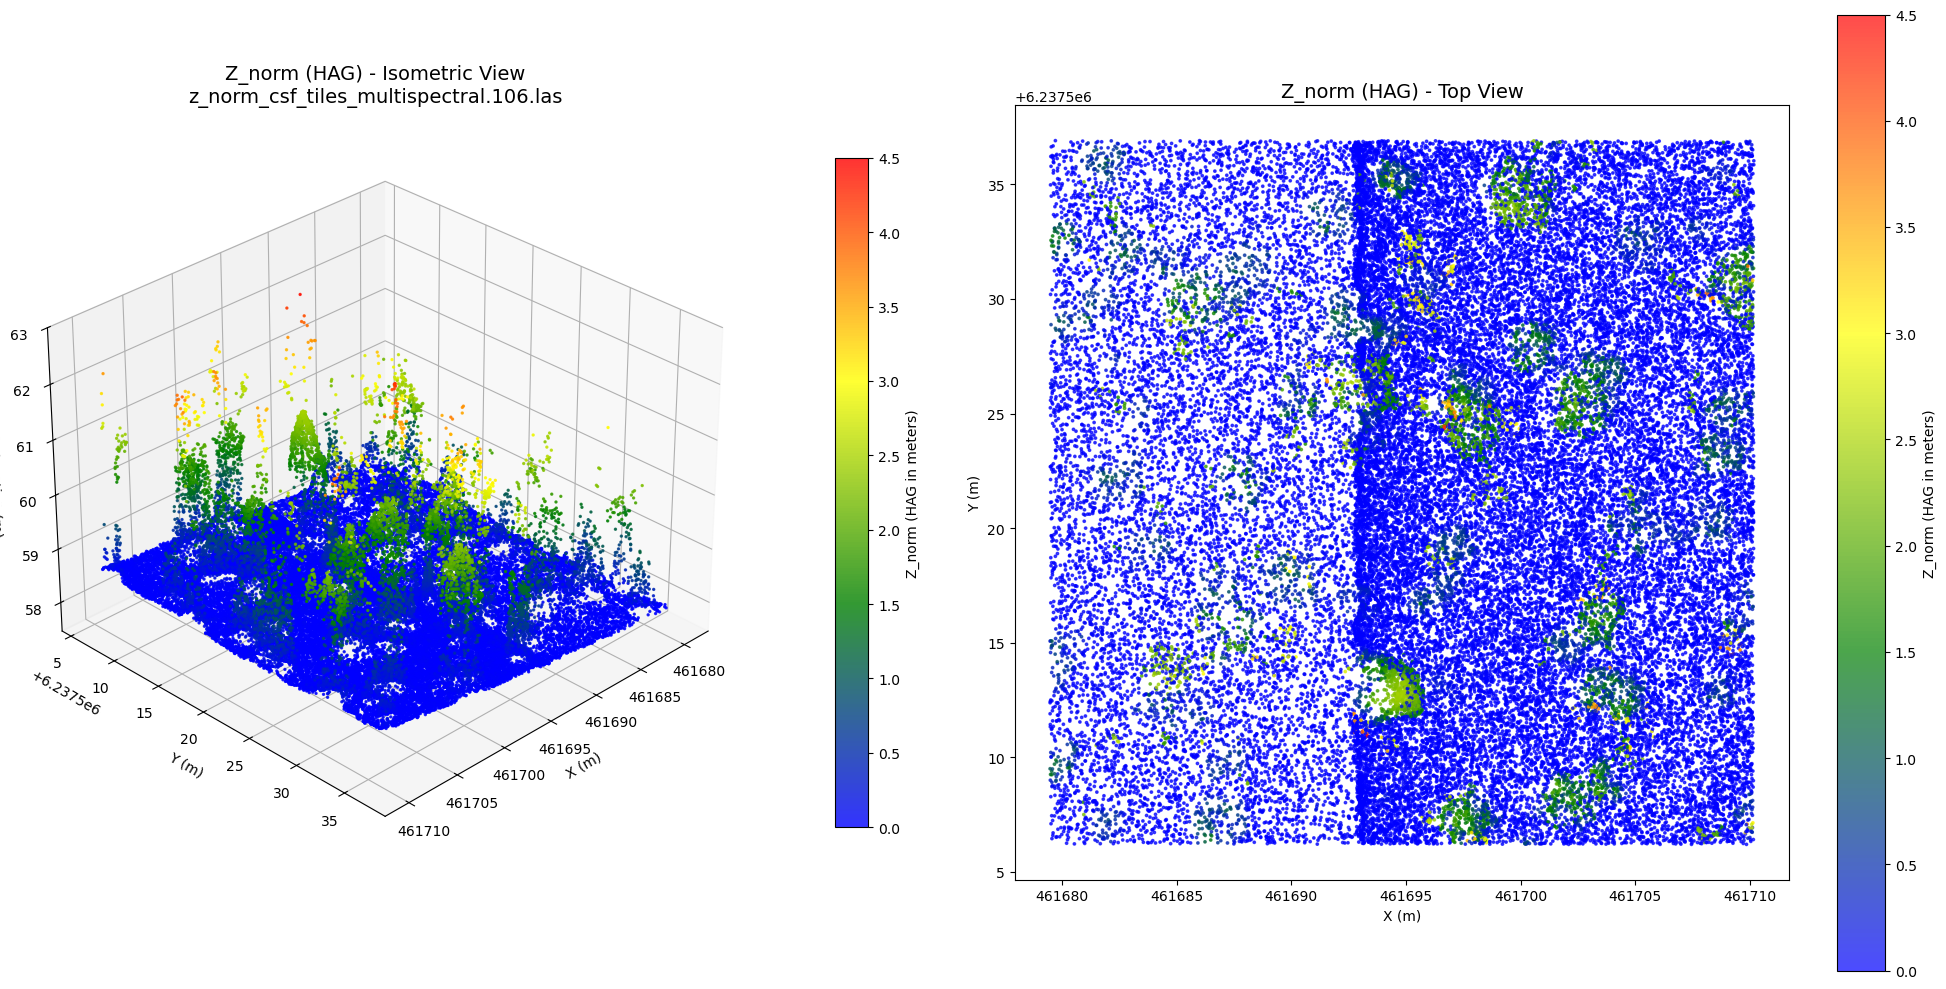

In [64]:
# --- Standalone Z_norm Visualization (Matplotlib) ---
# Visualize any z_norm file directly
import laspy
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LinearSegmentedColormap

# Load the file (can change to any z_norm file)
las_file = Path('/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/z_norm/csf/z_norm_csf_tiles_multispectral.106.las')

if las_file.exists():
    las = laspy.read(las_file)
    z_norm = np.asarray(las.Z_norm, dtype=np.float32)
    
    print(f"Loaded {len(las.points):,} points from {las_file.name}")
    print(f"Z_norm range: {z_norm.min():.3f} - {z_norm.max():.3f} m")
    print(f"Elevation range: {las.z.min():.3f} - {las.z.max():.3f} m")
    
    # Downsample for visualization
    max_pts = 50000
    idx = np.random.choice(len(las.x), size=min(max_pts, len(las.x)), replace=False)
    x = las.x[idx]
    y = las.y[idx]
    z = las.z[idx]
    hag = z_norm[idx]
    
    # Create custom colormap: blue -> green -> yellow -> red (matching CloudCompare)
    colors_bgyr = ['blue', 'green', 'yellow', 'red']
    cmap_bgyr = LinearSegmentedColormap.from_list('bgyr', colors_bgyr, N=256)
    
    # Create visualization
    fig = plt.figure(figsize=(20, 10))
    
    # 3D Isometric view (like CloudCompare)
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    sc = ax1.scatter(x, y, z, s=2, c=hag, cmap=cmap_bgyr, alpha=0.8, vmin=0, vmax=4.5)
    ax1.set_title(f'Z_norm (HAG) - Isometric View\n{las_file.name}', fontsize=14, pad=20)
    ax1.set_xlabel('X (m)', fontsize=10)
    ax1.set_ylabel('Y (m)', fontsize=10)
    ax1.set_zlabel('Z elevation (m)', fontsize=10)
    ax1.view_init(elev=30, azim=45)
    plt.colorbar(sc, ax=ax1, label='Z_norm (HAG in meters)', shrink=0.7, pad=0.1)
    
    # Top view
    ax2 = fig.add_subplot(1, 2, 2)
    sc = ax2.scatter(x, y, s=3, c=hag, cmap=cmap_bgyr, alpha=0.7, vmin=0, vmax=4.5)
    ax2.set_title('Z_norm (HAG) - Top View', fontsize=14)
    ax2.set_xlabel('X (m)', fontsize=10)
    ax2.set_ylabel('Y (m)', fontsize=10)
    ax2.set_aspect('equal')
    plt.colorbar(sc, ax=ax2, label='Z_norm (HAG in meters)')
    
    plt.tight_layout()
    
    # Save figure
    output_path = Path.cwd().parent / 'z_norm_visualization.png'
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    print(f"\n✅ Visualization saved to: {output_path}")
    
    plt.show()
else:
    print(f"❌ File not found: {las_file}")
    print("   Update the path or process tiles first")

In [65]:
# --- Interactive 3D Visualization with Open3D ---
try:
    import open3d as o3d
    open3d_available = True
except ImportError:
    open3d_available = False
    print("⚠️ Open3D not installed. Install with: pip install open3d")

if open3d_available and las_files:
    print("Creating interactive Open3D visualization with depth rendering...")
    
    # Helper function to create colormap
    def get_color_from_hag(hag_values, vmin=0, vmax=5):
        """Map HAG values to blue->green->yellow->red colormap"""
        import matplotlib.pyplot as plt
        from matplotlib.colors import LinearSegmentedColormap
        
        colors_bgyr = ['blue', 'green', 'yellow', 'red']
        cmap = LinearSegmentedColormap.from_list('bgyr', colors_bgyr, N=256)
        
        # Normalize and clip
        hag_norm = np.clip((hag_values - vmin) / (vmax - vmin), 0, 1)
        # Get RGB colors
        colors = cmap(hag_norm)[:, :3]  # Drop alpha channel
        return colors
    
    # Create Open3D point clouds for CSF and SMRF
    print("\nPreparing CSF point cloud...")
    pcd_csf = o3d.geometry.PointCloud()
    points_csf = np.column_stack([x_csf_n, y_csf_n, z_csf_n])
    pcd_csf.points = o3d.utility.Vector3dVector(points_csf)
    pcd_csf.colors = o3d.utility.Vector3dVector(get_color_from_hag(hag_csf_n, vmin=0, vmax=5))
    
    print("Preparing SMRF point cloud...")
    pcd_smrf = o3d.geometry.PointCloud()
    points_smrf = np.column_stack([x_smrf_n, y_smrf_n, z_smrf_n])
    pcd_smrf.points = o3d.utility.Vector3dVector(points_smrf)
    pcd_smrf.colors = o3d.utility.Vector3dVector(get_color_from_hag(hag_smrf_n, vmin=0, vmax=5))
    
    # Estimate normals for better shading (optional but improves depth perception)
    print("Computing normals for enhanced depth perception...")
    pcd_csf.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=0.5, max_nn=30))
    pcd_smrf.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=0.5, max_nn=30))
    
    # Visualize CSF
    print("\n" + "="*60)
    print("Opening CSF point cloud viewer...")
    print("="*60)
    print("Controls:")
    print("  • Left mouse: Rotate")
    print("  • Middle mouse / Ctrl+Left: Pan")
    print("  • Scroll wheel: Zoom")
    print("  • H: Print help in terminal")
    print("  • Q / ESC: Close window")
    print("="*60)
    
    o3d.visualization.draw_geometries(
        [pcd_csf],
        window_name="CSF HAG Point Cloud (Blue=Ground → Red=Tall Vegetation)",
        width=1200,
        height=800,
        point_show_normal=False
    )
    
    # Visualize SMRF
    print("\n" + "="*60)
    print("Opening SMRF point cloud viewer...")
    print("="*60)
    
    o3d.visualization.draw_geometries(
        [pcd_smrf],
        window_name="SMRF HAG Point Cloud (Blue=Ground → Red=Tall Vegetation)",
        width=1200,
        height=800,
        point_show_normal=False
    )
    
    print("\n✅ Open3D visualization complete!")
    print("   Normals computed for enhanced depth rendering")
    print("   Colormap: Blue (ground) → Green → Yellow → Red (tall vegetation)")

elif not open3d_available:
    print("\n💡 To enable interactive 3D visualization with Open3D:")
    print("   pip install open3d")
else:
    print("⚠️ No LAS files loaded. Run earlier cells first.")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Creating interactive Open3D visualization with depth rendering...

Preparing CSF point cloud...
Preparing SMRF point cloud...
Computing normals for enhanced depth perception...

Opening CSF point cloud viewer...
Controls:
  • Left mouse: Rotate
  • Middle mouse / Ctrl+Left: Pan
  • Scroll wheel: Zoom
  • H: Print help in terminal
  • Q / ESC: Close window
[Open3D WARNING] GLFW Error: Failed to detect any supported platform
[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create window
[Open3D WARNING] [DrawGeometries] Failed creating OpenGL window.

Opening SMRF point cloud viewer...
[Open3D WARNING] GLFW initialized for headless rendering.
[Open3D WARNING] GLFW Error: OSMesa: Library not found
[Open3D WARNING] Failed to create wi

CSF vs SMRF HAG Comparison:
  Mean difference: 0.048 m
  Std difference: 0.080 m
  Max difference: 0.507 m
  Min difference: -0.100 m


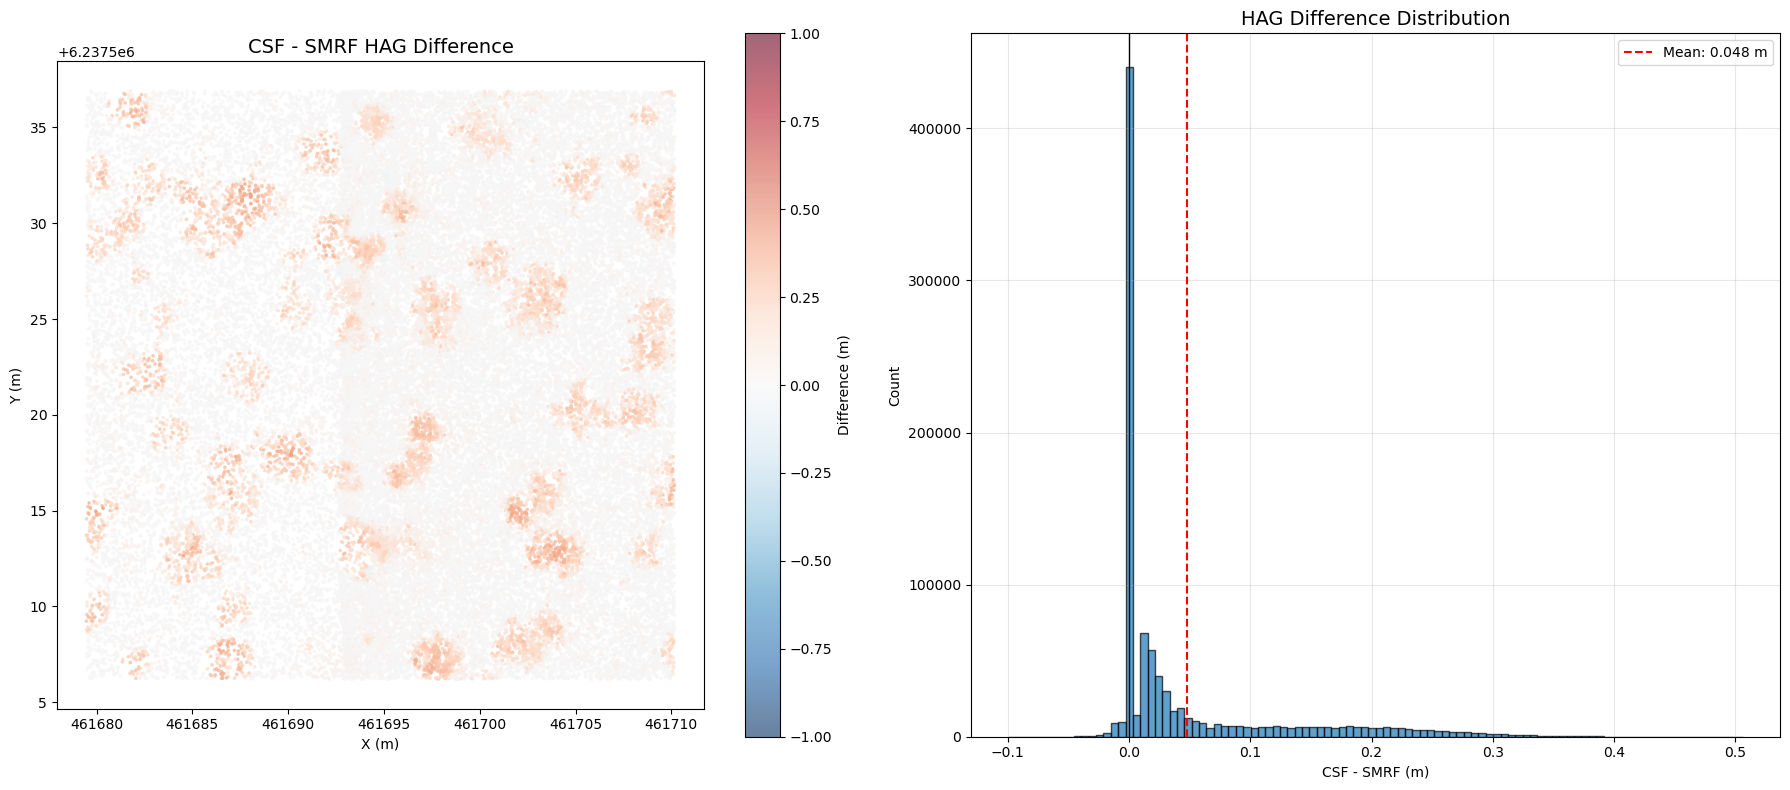

In [66]:
# --- Compare CSF vs SMRF HAG ---
if las_files:
    # Compute difference
    hag_diff = z_norm_csf - z_norm_smrf
    
    print("CSF vs SMRF HAG Comparison:")
    print(f"  Mean difference: {hag_diff.mean():.3f} m")
    print(f"  Std difference: {hag_diff.std():.3f} m")
    print(f"  Max difference: {hag_diff.max():.3f} m")
    print(f"  Min difference: {hag_diff.min():.3f} m")
    
    # Downsample for plotting
    idx = np.random.choice(len(hag_diff), size=min(max_pts, len(hag_diff)), replace=False)
    x_plot = las_znorm_csf.x[idx]
    y_plot = las_znorm_csf.y[idx]
    diff_plot = hag_diff[idx]
    
    # Create visualization
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    
    # Difference map
    ax = axes[0]
    sc = ax.scatter(x_plot, y_plot, s=3, c=diff_plot, cmap='RdBu_r', vmin=-1, vmax=1, alpha=0.6)
    ax.set_title('CSF - SMRF HAG Difference', fontsize=14)
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_aspect('equal')
    plt.colorbar(sc, ax=ax, label='Difference (m)')
    
    # Difference histogram
    ax = axes[1]
    ax.hist(hag_diff, bins=100, edgecolor='black', alpha=0.7)
    ax.axvline(hag_diff.mean(), color='red', linestyle='--', label=f'Mean: {hag_diff.mean():.3f} m')
    ax.axvline(0, color='black', linestyle='-', linewidth=1)
    ax.set_xlabel('CSF - SMRF (m)')
    ax.set_ylabel('Count')
    ax.set_title('HAG Difference Distribution', fontsize=14)
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [51]:
import importlib, groundnorm.dask_runner
importlib.reload(groundnorm.dask_runner)

from groundnorm.dask_runner import process_batch_csf
import inspect
print(inspect.signature(process_batch_csf))


(input_dir: pathlib.Path, output_base: pathlib.Path, *, pattern: str = '*.las', normalize: bool = True, n_workers: int = 4, resolution: float = 0.5, iterations: int = 500, threshold: float = 0.01, rigidness: int = 2) -> None


In [53]:
# --- Batch process all tiles (optional) ---
# Uncomment the code below to process ALL LAS files in the input directory
# This will process multiple tiles in parallel using the configured parameters

from groundnorm.dask_runner import process_batch_csf, process_batch_smrf

process_batch_csf(
    input_dir=INPUT_DIR,
    output_base=OUTPUT_BASE,
    pattern=LAS_PATTERN,
    normalize=True,
    n_workers=4,
    resolution=0.5,
    iterations=500,
    threshold=0.01,
    rigidness=2,
)

process_batch_smrf(
    input_dir=INPUT_DIR,
    output_base=OUTPUT_BASE,
    pattern=LAS_PATTERN,
    normalize=True,
    n_workers=4,
    slope=0.15,
    window=3.5,
    threshold=0.25,
    scalar=1.35,
)


print("📋 Batch processing code ready")
print(f"   Input: {INPUT_DIR}")
print(f"   Pattern: {LAS_PATTERN}")
print(f"   Files found: {len(list(INPUT_DIR.glob(LAS_PATTERN)))}")
print("\n💡 To process all tiles, uncomment the code above and run this cell")


Found 15 LAS files to process with CSF
Using 4 workers


CSF processing:   0%|          | 0/15 [00:00<?, ?it/s]

▶️  Running PDAL CSF on tiles_multispectral.121.las▶️  Running PDAL CSF on tiles_multispectral.106.las

▶️  Running PDAL CSF on tiles_multispectral.113.las
▶️  Running PDAL CSF on tiles_multispectral.109.las


((PDALPDAL  DebugDebug) ) Debugging...Debugging...

(PDAL Debug) Debugging...
(PDAL Debug) Debugging...
(pdal pipeline Debug) Executing pipeline in standard mode.(
pdal pipeline Debug) Executing pipeline in standard mode.
(pdal pipeline Debug) Executing pipeline in standard mode.
(pdal pipeline Debug) Executing pipeline in standard mode.


✅ CSF ground LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/ground_classification/csf/csf_tiles_multispectral.106.las


(pdal pipeline filters.csf Debug) setPointCloud: 924122
(pdal pipeline filters.csf Debug) setPointCloud: 927343
(pdal pipeline filters.csf Debug) [0] Configuring terrain...
(pdal pipeline filters.csf Debug) 461710, 461679
(pdal pipeline filters.csf Debug) [0] Configuring cloth...
(pdal pipeline filters.csf Debug) [0]  - width: 65 height: 65
(pdal pipeline filters.csf Debug) [0] Rasterizing...
(pdal pipeline filters.csf Debug) [0] Configuring terrain...
(pdal pipeline filters.csf Debug) 461710, 461679
(pdal pipeline filters.csf Debug) [0] Configuring cloth...
(pdal pipeline filters.csf Debug) [0]  - width: 65 height: 65
(pdal pipeline filters.csf Debug) [0] Rasterizing...
(pdal pipeline filters.csf Debug) [0] Simulating...
(pdal pipeline filters.csf Debug) [0] Simulating...
(pdal pipeline writers.las Debug) Wrote 271659 points to the LAS file
(pdal pipeline writers.las Debug) Wrote 246510 points to the LAS file


... (83 outputs left out)

SMRF processing:  93%|█████████▎| 14/15 [00:12<00:00,  1.02it/s]

✅ tiles_multispectral.93
✅ Wrote normalized LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/z_norm/smrf/z_norm_smrf_tiles_multispectral.96.las
   HAG stats (m): min=0.000, median=0.000, max=4.377
   Ground pts: 1,325,153, All pts: 1,620,007, k=3


SMRF processing: 100%|██████████| 15/15 [00:13<00:00,  1.12it/s]

✅ tiles_multispectral.96

🎉 SMRF processing complete!
📋 Batch processing code ready
   Input: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/icp
   Pattern: tiles_multispectral*.las
   Files found: 15

💡 To process all tiles, uncomment the code above and run this cell
